In [2]:
# ---- cell 1: imports (your existing cell, plus importlib) ----
from google.colab import drive
drive.mount('/content/drive')
!pip install -q wfdb
import os, sys, io, contextlib, hashlib, inspect, importlib
os.chdir('/content/drive/MyDrive/FYP'); sys.path.insert(0, os.getcwd())



import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import softmax
from src import config as C
from src.calibration import fit_temperature, ece, brier
from src.selective import *


d = np.load(C.PROC / 'oof_ds1_v6_base.npz')
L = d['logits']                    # [seed, n, 4]
y, rec = d['y'], d['rec']
Lens = L.mean(0)                   # ensemble by logit averaging
pred = Lens.argmax(1); correct = pred == y
print('ensemble acc', correct.mean().round(3))

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 1.5 MB/s eta 0:00:00
ensemble acc 0.837


In [3]:
T = fit_temperature(Lens, y)
P_raw, P_cal = softmax(Lens, 1), softmax(Lens / T, 1)
print('T =', round(T, 3))
for name, P in [('raw', P_raw), ('temp-scaled', P_cal)]:
    print(f'{name:12s} ECE {ece(P, y):.4f} | Brier {brier(P, y):.4f}')

T = 1.289
raw          ECE 0.0476 | Brier 0.2628
temp-scaled  ECE 0.0321 | Brier 0.2617


In [4]:
scores = {'MSP raw': P_raw.max(1), 'MSP calibrated': P_cal.max(1),
          'neg. entropy (cal.)': (P_cal * np.log(P_cal + 1e-12)).sum(1)}
levels = [1.0, 0.95, 0.9, 0.8, 0.7]
base_risk = 1 - correct.mean()
rows = []
for name, s in scores.items():
    rows.append([name, round(aurc(s, correct), 4)] +
                [round(selective_risk(accept_at_coverage(s, c), correct), 4) for c in levels])
rows.append(['random', round(base_risk, 4)] + [round(base_risk, 4)] * len(levels))
rows.append(['oracle', round(aurc(correct.astype(float), correct), 4)] +
            [round(selective_risk(oracle_accept(correct, c), correct), 4) for c in levels])
print(pd.DataFrame(rows, columns=['method', 'AURC'] + [f'risk@{int(c*100)}%' for c in levels]).to_string(index=False))

             method   AURC  risk@100%  risk@95%  risk@90%  risk@80%  risk@70%
            MSP raw 0.0744     0.1632    0.1430    0.1306    0.1124    0.0940
     MSP calibrated 0.0728     0.1632    0.1428    0.1293    0.1114    0.0919
neg. entropy (cal.) 0.0706     0.1632    0.1406    0.1296    0.1131    0.0872
             random 0.1632     0.1632    0.1632    0.1632    0.1632    0.1632
             oracle 0.0141     0.1632    0.1192    0.0703    0.0000    0.0000


In [5]:
s = scores['MSP calibrated']
out = []
for c in levels[1:]:
    cc = class_coverage(accept_at_coverage(s, c), y)
    out.append([f'{int(c*100)}%', *cc.round(3), round(np.nanmax(cc[:3]) - np.nanmin(cc[:3]), 3)])
print(pd.DataFrame(out, columns=['coverage'] + C.CLASSES + ['gap N/S/V']).to_string(index=False))
print('F is descriptive only (one dominant record).')

coverage     N     S     V     F  gap N/S/V
     95% 0.949 0.971 0.962 0.911      0.022
     90% 0.898 0.898 0.933 0.858      0.035
     80% 0.796 0.741 0.871 0.711      0.130
     70% 0.697 0.582 0.786 0.542      0.205
F is descriptive only (one dominant record).


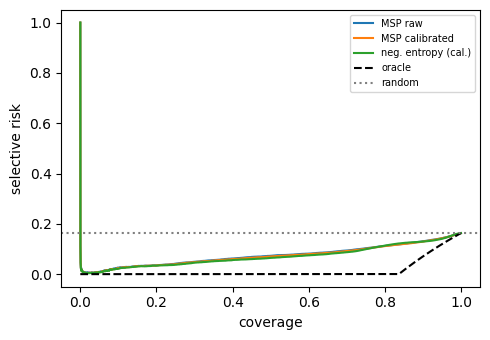

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
for name, s_ in scores.items():
    cov, risk = risk_coverage(s_, correct); ax.plot(cov, risk, label=name)
cov, risk = risk_coverage(correct.astype(float), correct); ax.plot(cov, risk, 'k--', label='oracle')
ax.axhline(base_risk, color='grey', ls=':', label='random')
ax.set_xlabel('coverage'); ax.set_ylabel('selective risk'); ax.legend(fontsize=7); plt.tight_layout()

In [7]:

# ---- cell 6: per-record errors and how many a confidence gate removes (80% coverage) ----
s_cal = scores['MSP calibrated']
acc80 = accept_at_coverage(s_cal, 0.8)
df = pd.DataFrame({'rec': rec, 'err': ~correct, 'rej80': ~acc80})
t = df.groupby('rec').agg(n=('err', 'size'), errors=('err', 'sum'), rejected=('rej80', 'sum'))
t['acc'] = 1 - t.errors / t.n
t['err_share'] = t.errors / t.errors.sum()
t['errors_removed'] = df[df.err & df.rej80].groupby('rec').size().reindex(t.index).fillna(0)
t['frac_err_removed'] = np.where(t.errors > 0, t.errors_removed / t.errors, np.nan)
top = t.sort_values('err_share', ascending=False)
print(top.head(8).round(3).to_string())
print('top-3 records share of all errors:', top.err_share.head(3).sum().round(3), list(top.index[:3]))
print('overall: errors removed at 80% coverage =',
      round(df[df.err & df.rej80].shape[0] / df.err.sum(), 3), '(random 0.20, oracle 1.00)')


        n  errors  rejected    acc  err_share  errors_removed  frac_err_removed
rec                                                                            
118  2277    2117       307  0.070      0.244           218.0             0.103
203  2976    1725      1805  0.420      0.199          1219.0             0.707
207  1859    1519       474  0.183      0.175           420.0             0.276
115  1952     686      1918  0.649      0.079           676.0             0.985
230  2255     490       894  0.783      0.056           485.0             0.990
208  2951     468       226  0.841      0.054           148.0             0.316
223  2605     375       250  0.856      0.043            81.0             0.216
209  3005     285       143  0.905      0.033            65.0             0.228
top-3 records share of all errors: 0.618 [118, 203, 207]
overall: errors removed at 80% coverage = 0.454 (random 0.20, oracle 1.00)


In [8]:

# ---- cell 7: subject-level bootstrap at 80% coverage (201 and 202 are one subject) ----
subj = np.where(rec == 202, 201, rec)
subjects = np.unique(subj)
idx_by = {s: np.where(subj == s)[0] for s in subjects}
s_ent = scores['neg. entropy (cal.)']

def stats(idx, cov=0.8):
    yy, cc = y[idx], correct[idx]
    a = accept_at_coverage(s_cal[idx], cov)
    k = class_coverage(a, yy)
    return {'risk': selective_risk(a, cc),
            'cov_N': k[0], 'cov_S': k[1], 'cov_V': k[2], 'cov_F': k[3],
            'gap_NSV': np.nanmax(k[:3]) - np.nanmin(k[:3]),
            'AURC_msp': aurc(s_cal[idx], cc), 'AURC_ent': aurc(s_ent[idx], cc)}

point = stats(np.arange(len(y)))
B, rng, boot = 1000, np.random.default_rng(0), []          # use 2000-5000 for the final analysis
for _ in range(B):
    pick = rng.choice(subjects, len(subjects), replace=True)
    r = stats(np.concatenate([idx_by[s] for s in pick]))
    r['AURC_ent_minus_msp'] = r['AURC_ent'] - r['AURC_msp']
    boot.append(r)
boot = pd.DataFrame(boot)
rows = []
for k, v in point.items():
    lo, hi = np.nanpercentile(boot[k], [2.5, 97.5])
    note = ''
    if k.startswith('cov_'):
        note = 'includes 0.80 (class-neutral)' if lo <= 0.8 <= hi else 'EXCLUDES 0.80'
    rows.append([k, round(v, 4), round(lo, 4), round(hi, 4), int(boot[k].notna().sum()), note])
lo, hi = np.nanpercentile(boot['AURC_ent_minus_msp'], [2.5, 97.5])
rows.append(['AURC_ent - AURC_msp', round(point['AURC_ent'] - point['AURC_msp'], 4),
             round(lo, 4), round(hi, 4), B, 'includes 0' if lo <= 0 <= hi else 'EXCLUDES 0'])
print(f'{len(subjects)} subjects, {B} resamples (95% percentile intervals; cov_* is coverage of that true class at 80% overall coverage)')
print(pd.DataFrame(rows, columns=['stat', 'point', 'ci_lo', 'ci_hi', 'n_valid', 'note']).to_string(index=False))


22 subjects, 1000 resamples (95% percentile intervals; cov_* is coverage of that true class at 80% overall coverage)
               stat   point   ci_lo  ci_hi  n_valid                          note
               risk  0.1114  0.0270 0.2266     1000                              
              cov_N  0.7964  0.7852 0.8113     1000 includes 0.80 (class-neutral)
              cov_S  0.7407  0.4958 0.9182     1000 includes 0.80 (class-neutral)
              cov_V  0.8708  0.7121 0.9438     1000 includes 0.80 (class-neutral)
              cov_F  0.7108  0.4332 0.8351     1000 includes 0.80 (class-neutral)
            gap_NSV  0.1300  0.0350 0.3340     1000                              
           AURC_msp  0.0728  0.0208 0.1648     1000                              
           AURC_ent  0.0706  0.0218 0.1576     1000                              
AURC_ent - AURC_msp -0.0022 -0.0093 0.0040     1000                    includes 0


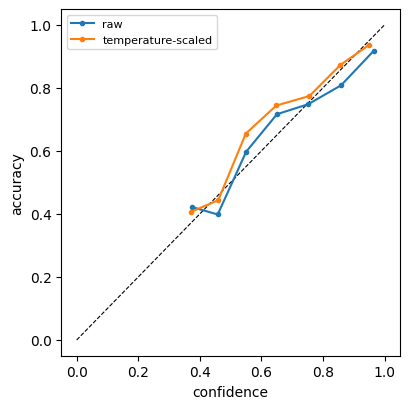

In [9]:

# ---- cell 8: reliability diagram, saved for the report ----
def reliability(P, n_bins=10):
    conf, ok = P.max(1), (P.argmax(1) == y)
    edges = np.linspace(0, 1, n_bins + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 30:
            xs.append(conf[m].mean()); ys.append(ok[m].mean())
    return xs, ys

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
for name, P in [('raw', P_raw), ('temperature-scaled', P_cal)]:
    xs, ys = reliability(P); ax.plot(xs, ys, marker='o', ms=3, label=name)
ax.set_xlabel('confidence'); ax.set_ylabel('accuracy'); ax.legend(fontsize=8); plt.tight_layout()
fig.savefig(C.PROC / 'reliability_v6.png', dpi=200)

In [ ]:
# ===== 03_confidence_rejection.ipynb : add these cells after cell 5 =====
# Needs the variables from cells 1-4: y, rec, correct, P_raw, P_cal, scores, C, np, pd, plt

# ---- cell 6: per-record errors and how many a confidence gate removes (80% coverage) ----
s_cal = scores['MSP calibrated']
acc80 = accept_at_coverage(s_cal, 0.8)
df = pd.DataFrame({'rec': rec, 'err': ~correct, 'rej80': ~acc80})
t = df.groupby('rec').agg(n=('err', 'size'), errors=('err', 'sum'), rejected=('rej80', 'sum'))
t['acc'] = 1 - t.errors / t.n
t['err_share'] = t.errors / t.errors.sum()
t['errors_removed'] = df[df.err & df.rej80].groupby('rec').size().reindex(t.index).fillna(0)
t['frac_err_removed'] = np.where(t.errors > 0, t.errors_removed / t.errors, np.nan)
top = t.sort_values('err_share', ascending=False)
print(top.head(8).round(3).to_string())
print('top-3 records share of all errors:', top.err_share.head(3).sum().round(3), list(top.index[:3]))
print('overall: errors removed at 80% coverage =',
      round(df[df.err & df.rej80].shape[0] / df.err.sum(), 3), '(random 0.20, oracle 1.00)')

# ---- cell 7: subject-level bootstrap at 80% coverage (201 and 202 are one subject) ----
subj = np.where(rec == 202, 201, rec)
subjects = np.unique(subj)
idx_by = {s: np.where(subj == s)[0] for s in subjects}
s_ent = scores['neg. entropy (cal.)']

def stats(idx, cov=0.8):
    yy, cc = y[idx], correct[idx]
    a = accept_at_coverage(s_cal[idx], cov)
    k = class_coverage(a, yy)
    return {'risk': selective_risk(a, cc),
            'cov_N': k[0], 'cov_S': k[1], 'cov_V': k[2], 'cov_F': k[3],
            'gap_NSV': np.nanmax(k[:3]) - np.nanmin(k[:3]),
            'AURC_msp': aurc(s_cal[idx], cc), 'AURC_ent': aurc(s_ent[idx], cc)}

point = stats(np.arange(len(y)))
B, rng, boot = 1000, np.random.default_rng(0), []          # use 2000-5000 for the final analysis
for _ in range(B):
    pick = rng.choice(subjects, len(subjects), replace=True)
    r = stats(np.concatenate([idx_by[s] for s in pick]))
    r['AURC_ent_minus_msp'] = r['AURC_ent'] - r['AURC_msp']
    boot.append(r)
boot = pd.DataFrame(boot)
rows = []
for k, v in point.items():
    lo, hi = np.nanpercentile(boot[k], [2.5, 97.5])
    note = ''
    if k.startswith('cov_'):
        note = 'includes 0.80 (class-neutral)' if lo <= 0.8 <= hi else 'EXCLUDES 0.80'
    rows.append([k, round(v, 4), round(lo, 4), round(hi, 4), int(boot[k].notna().sum()), note])
lo, hi = np.nanpercentile(boot['AURC_ent_minus_msp'], [2.5, 97.5])
rows.append(['AURC_ent - AURC_msp', round(point['AURC_ent'] - point['AURC_msp'], 4),
             round(lo, 4), round(hi, 4), B, 'includes 0' if lo <= 0 <= hi else 'EXCLUDES 0'])
print(f'{len(subjects)} subjects, {B} resamples (95% percentile intervals; cov_* is coverage of that true class at 80% overall coverage)')
print(pd.DataFrame(rows, columns=['stat', 'point', 'ci_lo', 'ci_hi', 'n_valid', 'note']).to_string(index=False))

# ---- cell 8: reliability diagram, saved for the report ----
def reliability(P, n_bins=10):
    conf, ok = P.max(1), (P.argmax(1) == y)
    edges = np.linspace(0, 1, n_bins + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 30:
            xs.append(conf[m].mean()); ys.append(ok[m].mean())
    return xs, ys

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
for name, P in [('raw', P_raw), ('temperature-scaled', P_cal)]:
    xs, ys = reliability(P); ax.plot(xs, ys, marker='o', ms=3, label=name)
ax.set_xlabel('confidence'); ax.set_ylabel('accuracy'); ax.legend(fontsize=8); plt.tight_layout()
fig.savefig(C.PROC / 'reliability_v6.png', dpi=200)

In [10]:

import os
import hashlib

TARGETS = {
    "oof_ds1_v6_subjectfolds.npz":
        "7138c8cf977be01aa1116ab78cab49da344413fd8ec5d8551846f39e37ab1e6c"
}

SEARCH_ROOTS = [
    "/content",
    "/content/drive/MyDrive/FYP",
]

for filename, expected_hash in TARGETS.items():
    print(f"\nLooking for: {filename}")
    found = False

    for root in SEARCH_ROOTS:
        if not os.path.exists(root):
            continue

        for current, dirs, files in os.walk(root):
            # Avoid searching large unrelated cache folders
            dirs[:] = [
                d for d in dirs
                if d not in {"node_modules", ".cache", "__pycache__"}
            ]

            if filename not in files:
                continue

            path = os.path.join(current, filename)
            found = True

            sha256 = hashlib.sha256()
            with open(path, "rb") as f:
                for chunk in iter(lambda: f.read(1024 * 1024), b""):
                    sha256.update(chunk)

            actual_hash = sha256.hexdigest()
            print("Path:", path)
            print("SHA256:", actual_hash)
            print("Matches project log:", actual_hash == expected_hash)

    if not found:
        print("NOT FOUND in the searched folders.")


Looking for: oof_ds1_v6_subjectfolds.npz
Path: /content/drive/MyDrive/FYP/data/processed/oof_ds1_v6_subjectfolds.npz
SHA256: 7138c8cf977be01aa1116ab78cab49da344413fd8ec5d8551846f39e37ab1e6c
Matches project log: True
Path: /content/drive/MyDrive/FYP/data/processed/oof_ds1_v6_subjectfolds.npz
SHA256: 7138c8cf977be01aa1116ab78cab49da344413fd8ec5d8551846f39e37ab1e6c
Matches project log: True


In [11]:

from pathlib import Path
import hashlib
import numpy as np

folder = Path("/content/drive/MyDrive/FYP/data/processed")
names = [
    "oof_ds1_v6_subjectfolds.npz",
    "oof_ds1_v6_base.npz",
]

loaded = {}

for name in names:
    path = folder / name
    print(f"\n{'=' * 60}\n{name}")

    if not path.exists():
        print("NOT FOUND")
        continue

    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    print("SHA256:", digest)

    archive = np.load(path, allow_pickle=False)
    loaded[name] = {key: archive[key].copy() for key in archive.files}

    for key, arr in loaded[name].items():
        print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")

a_name, b_name = names
if a_name in loaded and b_name in loaded:
    a, b = loaded[a_name], loaded[b_name]
    print("\nCOMPARISON")
    print("Only in subjectfolds:", sorted(set(a) - set(b)))
    print("Only in base:", sorted(set(b) - set(a)))

    for key in sorted(set(a) & set(b)):
        x, y = a[key], b[key]
        if x.shape != y.shape:
            print(f"{key}: DIFFERENT SHAPES {x.shape} vs {y.shape}")
        elif np.array_equal(x, y, equal_nan=True):
            print(f"{key}: IDENTICAL")
        elif np.issubdtype(x.dtype, np.number) and np.issubdtype(y.dtype, np.number):
            print(
                f"{key}: DIFFERENT; "
                f"max_abs_diff={np.max(np.abs(x.astype(float)-y.astype(float))):.8g}"
            )
        else:
            print(f"{key}: DIFFERENT VALUES")


oof_ds1_v6_subjectfolds.npz
SHA256: 7138c8cf977be01aa1116ab78cab49da344413fd8ec5d8551846f39e37ab1e6c
  logits: shape=(3, 53138, 4), dtype=float32
  y: shape=(53138,), dtype=int64
  rec: shape=(53138,), dtype=int64
  ridx: shape=(53138,), dtype=int64
  fold: shape=(53138,), dtype=int64
  seeds: shape=(3,), dtype=int64

oof_ds1_v6_base.npz
SHA256: 2415e563a8b64251af5cd4b8182c2098e44793f83814be5274d528acbadc1cac
  logits: shape=(3, 53138, 4), dtype=float32
  y: shape=(53138,), dtype=int64
  rec: shape=(53138,), dtype=int64
  ridx: shape=(53138,), dtype=int64
  fold: shape=(53138,), dtype=int64
  seeds: shape=(3,), dtype=int64

COMPARISON
Only in subjectfolds: []
Only in base: []
fold: DIFFERENT; max_abs_diff=3
logits: DIFFERENT; max_abs_diff=11.698694
rec: IDENTICAL
ridx: IDENTICAL
seeds: IDENTICAL
y: IDENTICAL
